In [38]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import pandas as pd
from pathlib import Path

save_dir = Path('/content/drive/MyDrive/DIP_Final_Project/Ass2_Report_Figures')
save_dir.mkdir(parents=True, exist_ok=True)


**Image Path**

In [40]:
cotton_path = '/content/drive/MyDrive/DIP_Final_Project/Sample_data/CAM2_20260923_163214_100%cotton.png'
linen_rayon_path = '/content/drive/MyDrive/DIP_Final_Project/Sample_data/CAM1_20260924_173152_55%linen_45%rayon.png'
poly_path = '/content/drive/MyDrive/DIP_Final_Project/Sample_data/CAM2_20260923_161722_100%polyester.png'

In [41]:
selected = {
    '100% Cotton': cotton_path,
    '55% Linen - 45% Rayon': linen_rayon_path,
    '100% Polyester': poly_path
}
images = {}

for name, path in selected.items():
    bgr = cv2.imread(path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    # Convert the color image to grayscale for DFT analysis
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    # Store both RGB and grayscale images for later processing
    images[name] = {
        'rgb': rgb,
        'gray': gray
    }

# A. IMAGE READING

In [42]:
info = []

for name, img in images.items():
    rgb = img['rgb']
    gray = img['gray']

    # Get image dimensions
    height, width = gray.shape

    # Collect basic image information
    info.append({
    'Image': name,
    'Size': f'{width} x {height}',
    'Channels': rgb.shape[2],
    'Bit depth': rgb.dtype.itemsize * 8,
    'Data type': str(rgb.dtype),
    'Min intensity': int(gray.min()),
    'Max intensity': int(gray.max())
})

# Display image information as a table
display(pd.DataFrame(info))

,Image,Size,Channels,Bit depth,Data type,Min intensity,Max intensity
0,100% Cotton,2464 x 2464,3,8,uint8,2,255
1,55% Linen - 45% Rayon,2464 x 2464,3,8,uint8,84,255
2,100% Polyester,2464 x 2464,3,8,uint8,19,255


All three images have the same resolution of 2464 × 2464 pixels, three channels, and 8-bit uint8 representation. Cotton spans almost the full grayscale range [2, 255], polyester spans [19, 255], while linen-rayon has a narrower range [84, 255] and contains no very dark pixels. Visually, cotton contains dense and irregular fine fibers, linen-rayon contains smoother yarn regions with loose filaments, while polyester shows a highly regular diagonal weave pattern.

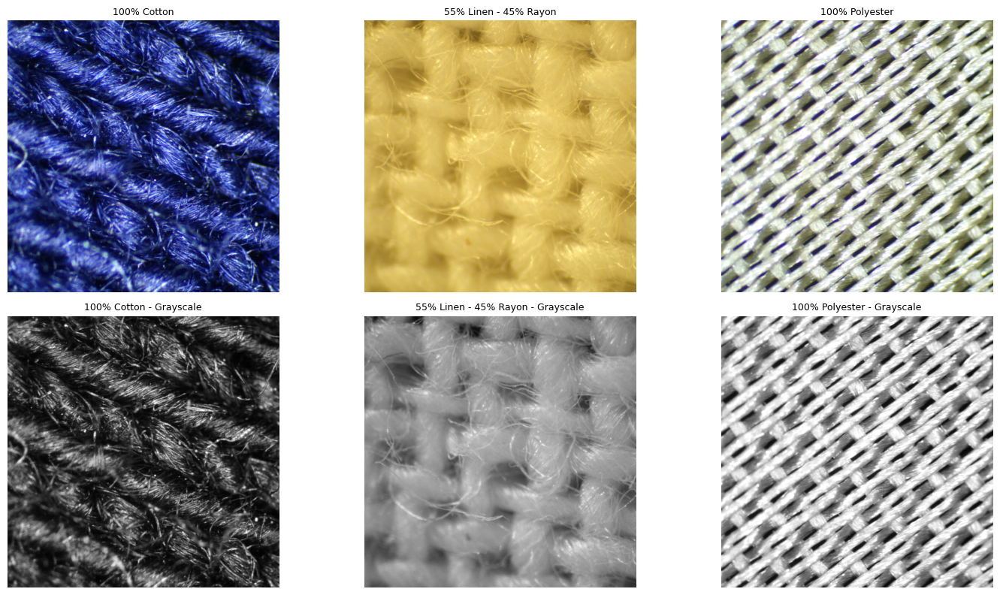

In [43]:
plt.figure(figsize=(15, 8))

for i, (name, img) in enumerate(images.items()):
    # Display the original RGB image
    plt.subplot(2, 3, i + 1)
    plt.imshow(img['rgb'])
    plt.title(name)
    plt.axis('off')

    # Display the corresponding grayscale image
    plt.subplot(2, 3, i + 4)
    plt.imshow(img['gray'], cmap='gray')
    plt.title(name + ' - Grayscale')
    plt.axis('off')

plt.tight_layout()
plt.show()

# B. Frequency-Domain Representation

B1. DFT, magnitude, and phase


Low-frequency components represent slowly varying information such as overall illumination and large fabric structures, while high-frequency components represent rapid intensity changes such as yarn boundaries, fine fibers, texture, and noise. After fftshift, low frequencies are located near the center of the spectrum, whereas higher frequencies appear farther toward the peripheral regions.

In [44]:
def compute_dft(gray):
    F = np.fft.fft2(gray)
    magnitude = np.log1p(np.abs(F))
    F_shift = np.fft.fftshift(F)
    centered_magnitude = np.log1p(np.abs(F_shift))
    phase = np.angle(F_shift)

    return F_shift, magnitude, centered_magnitude, phase

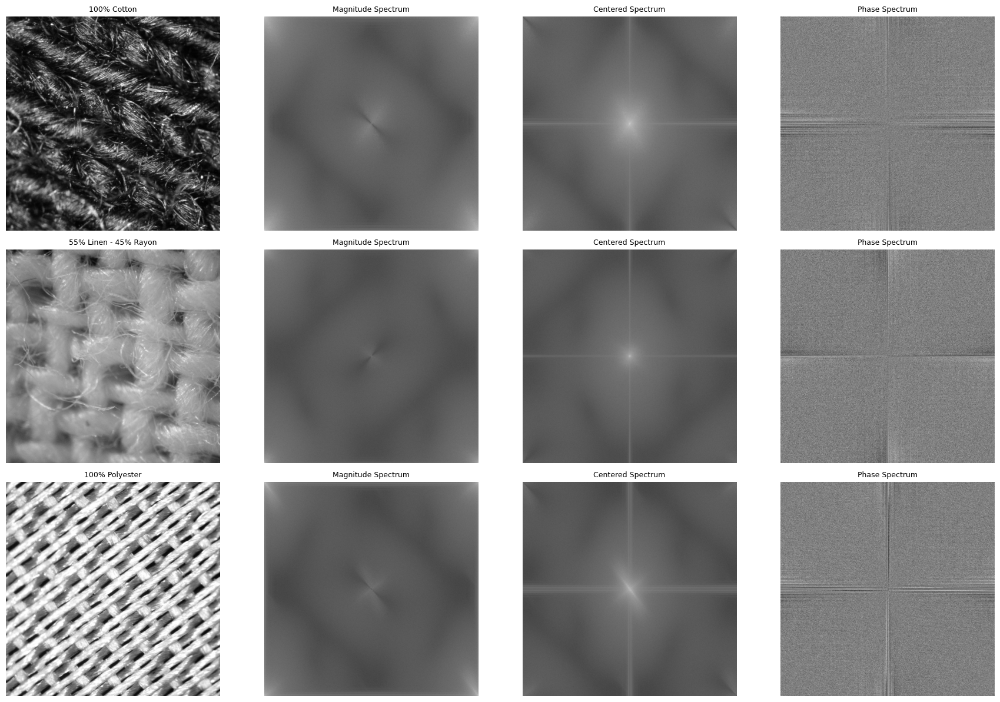

In [45]:
plt.figure(figsize=(18, 12))

for i, (name, img) in enumerate(images.items()):
    gray = img['gray']
    # Compute frequency-domain representations
    F_shift, magnitude, centered_magnitude, phase = compute_dft(gray)
    # Store the results for later processing
    images[name]['F_shift'] = F_shift
    images[name]['centered_magnitude'] = centered_magnitude
    images[name]['phase'] = phase

    plt.subplot(3, 4, i * 4 + 1)
    plt.imshow(gray, cmap='gray')
    plt.title(name)
    plt.axis('off')

    plt.subplot(3, 4, i * 4 + 2)
    plt.imshow(magnitude, cmap='gray')
    plt.title('Magnitude Spectrum')
    plt.axis('off')

    plt.subplot(3, 4, i * 4 + 3)
    plt.imshow(centered_magnitude, cmap='gray')
    plt.title('Centered Spectrum')
    plt.axis('off')

    plt.subplot(3, 4, i * 4 + 4)
    plt.imshow(phase, cmap='gray', vmin=-np.pi, vmax=np.pi)
    plt.title('Phase Spectrum')
    plt.axis('off')

plt.tight_layout()
plt.show()

After fftshift, all three spectra have their strongest components around the center. Cotton has a relatively broad and diffuse spectrum, consistent with its irregular fine-fiber texture. Linen-rayon has more energy concentrated near the center, matching its smoother large-scale structures. Polyester shows a clear diagonal spectral pattern, corresponding to the strong periodic and directional weave visible in the original image.

The magnitude spectrum represents the strength of the frequency components, while the phase contains their spatial arrangement. Although the phase images appear complex, phase information is necessary to reconstruct the original structures.

B2. IDFT

100% Cotton Mean error: 1.734835897263972e-14 Max error: 1.4210854715202004e-13
55% Linen - 45% Rayon Mean error: 3.3062653269224806e-14 Max error: 2.2737367544323206e-13
100% Polyester Mean error: 4.2894581999094864e-14 Max error: 2.7000623958883807e-13


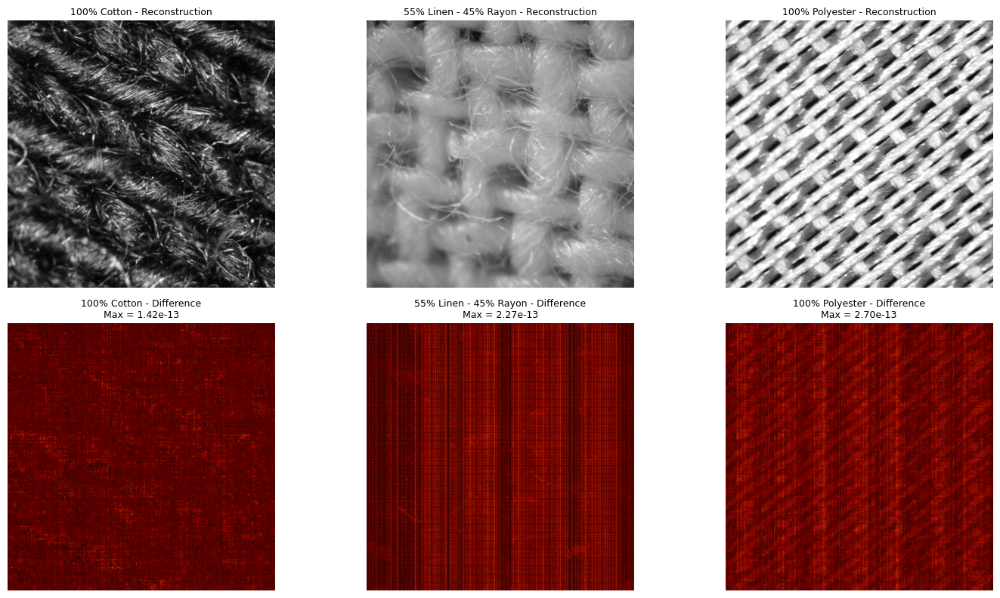

In [46]:
plt.figure(figsize=(15, 8))

for i, (name, img) in enumerate(images.items()):
    gray = img['gray']
    F_shift = img['F_shift']
    F = np.fft.ifftshift(F_shift)
    reconstructed = np.real(np.fft.ifft2(F))
    difference = np.abs(gray.astype(float) - reconstructed)

    print(
        name,
        'Mean error:',
        difference.mean(),
        'Max error:',
        difference.max()
    )

    # Display the reconstructed image
    plt.subplot(2, 3, i + 1)
    plt.imshow(reconstructed, cmap='gray')
    plt.title(name + ' - Reconstruction')
    plt.axis('off')

    # Display the reconstruction difference
    plt.subplot(2, 3, i + 4)
    plt.imshow(difference, cmap='hot')
    plt.title(
    f'{name} - Difference\n'
    f'Max = {difference.max():.2e}'
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

The reconstructed images are visually identical to the original grayscale images. The mean reconstruction errors are approximately $10^{-14}$, while the maximum errors are approximately $10^{-13}$. These values are negligible and result from floating-point numerical precision. Therefore, the forward DFT followed by the inverse DFT preserves the image information accurately. The visible structures in the difference plots are caused by automatic display scaling of extremely small numerical errors rather than meaningful reconstruction errors.

# C. Frequency-domain filtering

C1. Low-pass filtering

In [47]:
def distance_map(shape):
    height, width = shape
    u = np.arange(height)[:, None] - height // 2
    v = np.arange(width)[None, :] - width // 2
    return np.sqrt(u**2 + v**2)

def gaussian_lowpass(shape, sigma):
    D = distance_map(shape)
    # Gaussian low-pass filter
    H = np.exp(-(D**2) / (2 * sigma**2))
    return H

def frequency_filter(gray, H):
    F = np.fft.fft2(gray)
    F_shift = np.fft.fftshift(F)
    G_shift = F_shift * H
    G = np.fft.ifftshift(G_shift)
    output = np.real(np.fft.ifft2(G))
    return output, G_shift

C1.1. ILPF

In [48]:
def ideal_lowpass(shape, D0):
    # Compute the distance from each frequency point to the center
    D = distance_map(shape)
    # Preserve frequencies inside the cutoff radius
    H = (D <= D0).astype(float)

    return H

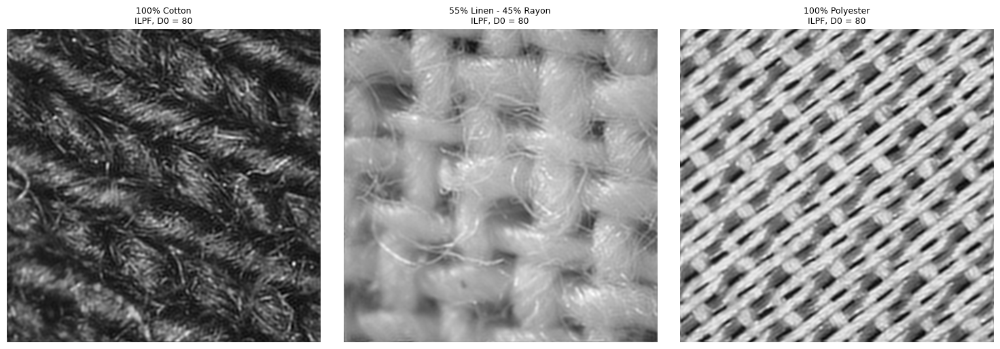

In [49]:
D0 = 80

plt.figure(figsize=(15, 5))

for i, (name, img) in enumerate(images.items()):
    gray = img['gray']

    # Create the ideal low-pass filter
    H = ideal_lowpass(gray.shape, D0)
    # Apply the filter in the frequency domain
    filtered, _ = frequency_filter(gray, H)

    plt.subplot(1, 3, i + 1)
    plt.imshow(filtered, cmap='gray')
    plt.title(f'{name}\nILPF, D0 = {D0}')
    plt.axis('off')

plt.tight_layout()
plt.show()

ILPF Mask + Filtered Spectrum

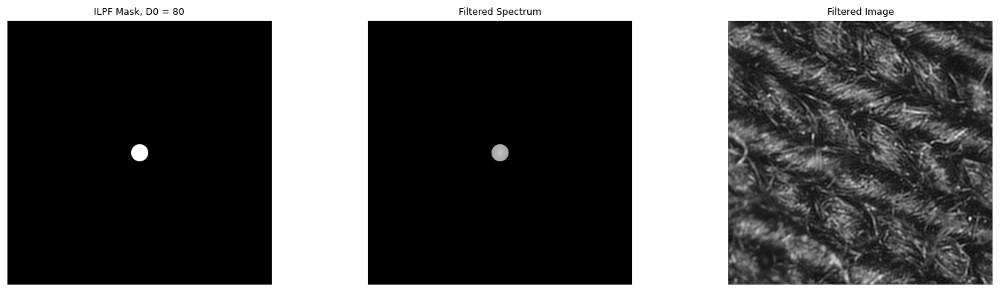

In [50]:
gray = images['100% Cotton']['gray']
D0 = 80

# Create the ideal low-pass filter
H = ideal_lowpass(gray.shape, D0)
# Apply frequency-domain filtering
filtered, G_shift = frequency_filter(gray, H)
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap='gray')
plt.title(f'ILPF Mask, D0 = {D0}')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(G_shift)), cmap='gray')
plt.title('Filtered Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

With $D_0=80$, ILPF noticeably suppresses fine textile details while retaining the dominant yarn structures. Cotton loses many thin fiber details, linen-rayon becomes visibly smoother, and the repeated polyester weave remains identifiable but with softened boundaries. No strong ringing artifact is clearly visible at the current display scale.

C1.2. GLPF

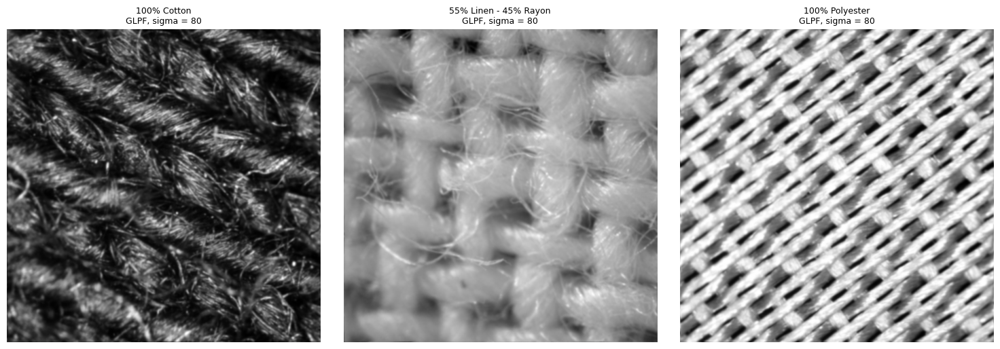

In [51]:
sigma = 80

plt.figure(figsize=(15, 5))

for i, (name, img) in enumerate(images.items()):
    gray = img['gray']

    # Create the Gaussian low-pass filter
    H = gaussian_lowpass(gray.shape, sigma)
    filtered, _ = frequency_filter(gray, H)

    plt.subplot(1, 3, i + 1)
    plt.imshow(filtered, cmap='gray')
    plt.title(f'{name}\nGLPF, sigma = {sigma}')
    plt.axis('off')

plt.tight_layout()
plt.show()

With $\sigma=80$, GLPF smooths fine structures in all three images while preserving their main fabric patterns. In cotton, thin fibers become less distinct. In linen-rayon, loose filaments and yarn boundaries become noticeably softer. In polyester, the regular diagonal weave remains clearly visible, but its edges become smoother.

GLPF: Mask + filtered spectrum

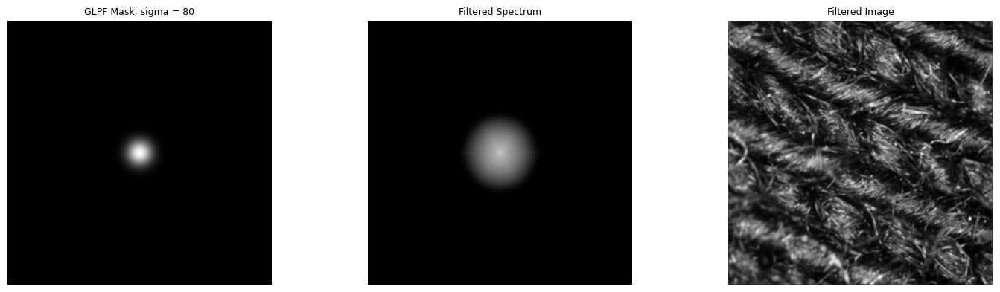

In [52]:
gray = images['100% Cotton']['gray']
sigma = 80

# Create the Gaussian low-pass filter
H = gaussian_lowpass(gray.shape, sigma)
# Apply the filter
filtered, G_shift = frequency_filter(gray, H)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap='gray')
plt.title(f'GLPF Mask, sigma = {sigma}')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(G_shift)), cmap='gray')
plt.title('Filtered Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

C1.3 Parameter experiment

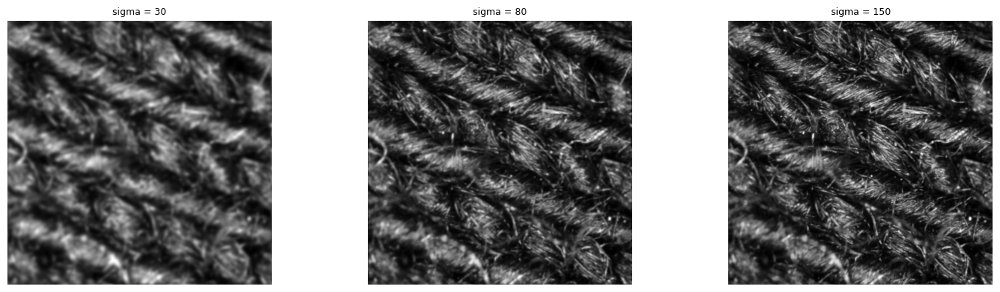

In [53]:
sigma_values = [30, 80, 150]
gray = images['100% Cotton']['gray']
plt.figure(figsize=(15, 4))
for i, sigma in enumerate(sigma_values):
    # Create the GLPF using the current sigma
    H = gaussian_lowpass(gray.shape, sigma)
    # Apply the filter
    filtered, _ = frequency_filter(gray, H)
    plt.subplot(1, 3, i + 1)
    plt.imshow(filtered, cmap='gray')
    plt.title(f'sigma = {sigma}')
    plt.axis('off')
plt.tight_layout()
plt.show()

At $\sigma=30$, the cotton image is strongly blurred and many individual fibers merge together. At $\sigma=80$, the main yarn structure is preserved while some fine fibers are suppressed. At $\sigma=150$, most fine fiber details are retained and the result is much closer to the original image. Therefore, increasing $\sigma$ allows a wider range of frequencies to pass.

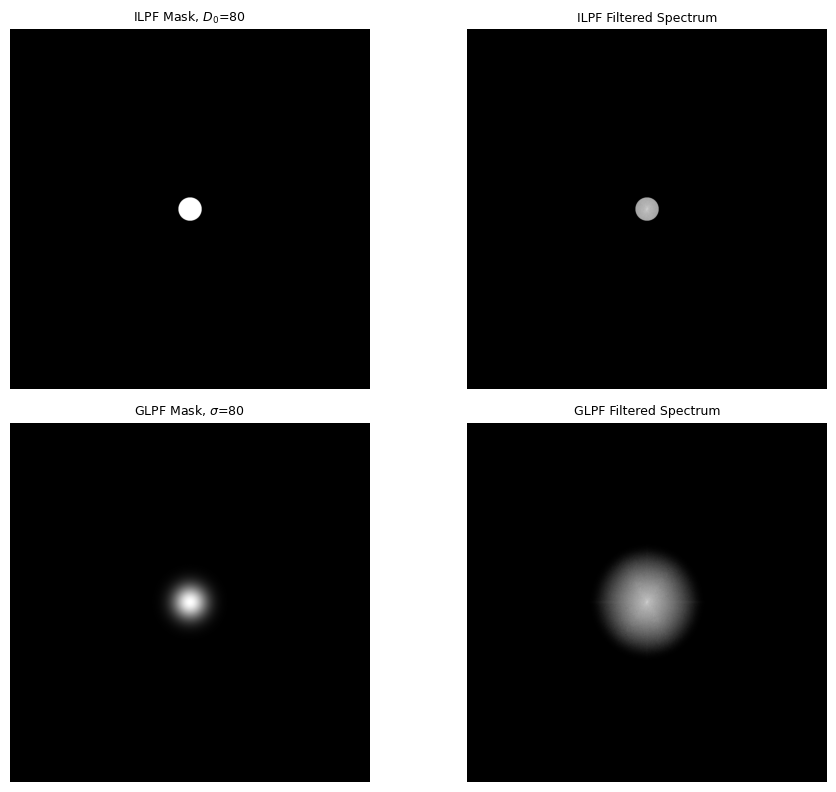

In [54]:
gray = images['100% Cotton']['gray']

D0 = 80
sigma = 80

# Create low-pass filters
H_ilpf = ideal_lowpass(gray.shape, D0)
H_glpf = gaussian_lowpass(gray.shape, sigma)

# Apply the filters
_, G_ilpf = frequency_filter(gray, H_ilpf)
_, G_glpf = frequency_filter(gray, H_glpf)

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(H_ilpf, cmap='gray')
plt.title(f'ILPF Mask, $D_0$={D0}')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(np.log1p(np.abs(G_ilpf)), cmap='gray')
plt.title('ILPF Filtered Spectrum')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(H_glpf, cmap='gray')
plt.title(f'GLPF Mask, $\\sigma$={sigma}')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(np.log1p(np.abs(G_glpf)), cmap='gray')
plt.title('GLPF Filtered Spectrum')
plt.axis('off')

plt.tight_layout()

# Save the LPF mask/spectrum figure for the report
plt.savefig(
    save_dir / 'fig_lpf_masks.png',
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.03
)

plt.show()


C2. High-pass filtering

In [55]:
def ideal_highpass(shape, D0):
    # Create the high-pass filter from the ideal low-pass filter
    return 1 - ideal_lowpass(shape, D0)

def gaussian_highpass(shape, sigma):
    # Create the high-pass filter from the Gaussian low-pass filter
    return 1 - gaussian_lowpass(shape, sigma)

C2.1. IHPF

In [56]:
def normalize_for_display(img):
    # Convert the result to a visible 0-255 range
    min_val = img.min()
    max_val = img.max()
    normalized = 255 * (img - min_val) / (max_val - min_val)
    return normalized.astype(np.uint8)

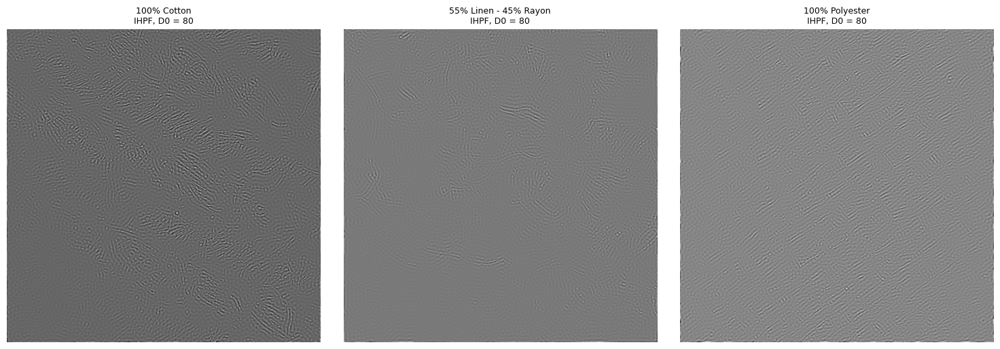

In [57]:
D0 = 80

plt.figure(figsize=(15, 5))

for i, (name, img) in enumerate(images.items()):
    gray = img['gray']

    # Create the ideal high-pass filter
    H = ideal_highpass(gray.shape, D0)

    # Extract high-frequency components
    highpass, _ = frequency_filter(gray, H)

    # Normalize only for visualization
    highpass_vis = normalize_for_display(highpass)

    plt.subplot(1, 3, i + 1)
    plt.imshow(highpass_vis, cmap='gray')
    plt.title(f'{name}\nIHPF, D0 = {D0}')
    plt.axis('off')

plt.tight_layout()
plt.show()

IHPF Mask + Filtered Spectrum

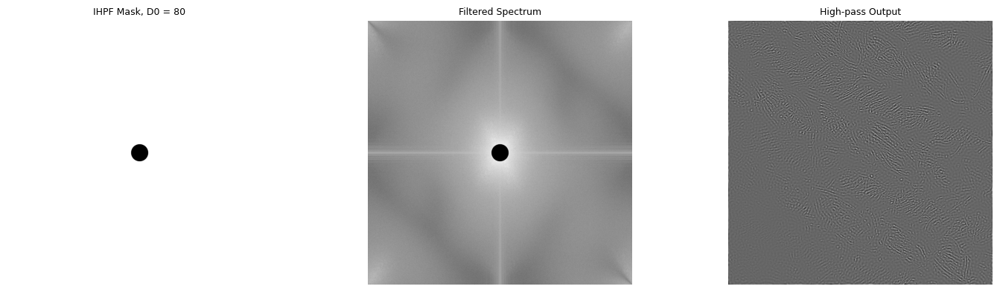

In [58]:
gray = images['100% Cotton']['gray']
D0 = 80
# Create the ideal high-pass filter
H = ideal_highpass(gray.shape, D0)
# Apply high-pass filtering
highpass, G_shift = frequency_filter(gray, H)
# Normalize the spatial result only for display
highpass_vis = normalize_for_display(highpass)
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap='gray')
plt.title(f'IHPF Mask, D0 = {D0}')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(G_shift)), cmap='gray')
plt.title('Filtered Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(highpass_vis, cmap='gray')
plt.title('High-pass Output')
plt.axis('off')

plt.tight_layout()
plt.show()

C2.2. GHPF

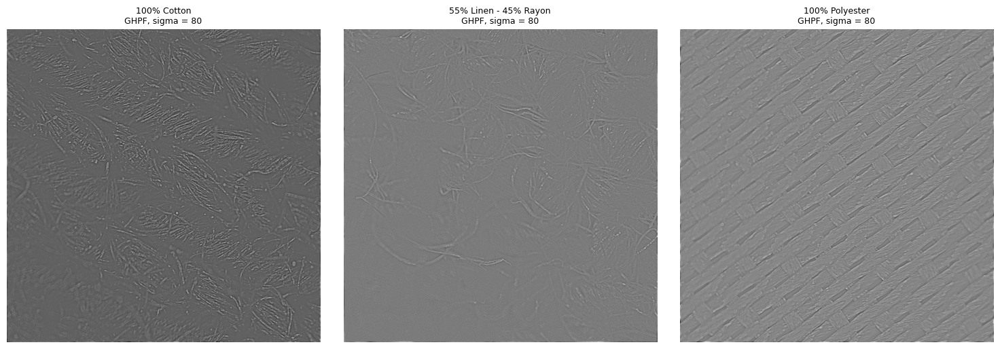

In [59]:
sigma = 80
plt.figure(figsize=(15, 5))
for i, (name, img) in enumerate(images.items()):
    gray = img['gray']
    # Create the Gaussian high-pass filter
    H = gaussian_highpass(gray.shape, sigma)
    # Extract the high-frequency components
    highpass, G_shift = frequency_filter(gray, H)
    # Normalize only for visualization
    highpass_vis = normalize_for_display(highpass)
    plt.subplot(1, 3, i + 1)
    plt.imshow(highpass_vis, cmap='gray')
    plt.title(f'{name}\nGHPF, sigma = {sigma}')
    plt.axis('off')

plt.tight_layout()
plt.show()

GHPF Mask + Filtered Spectrum

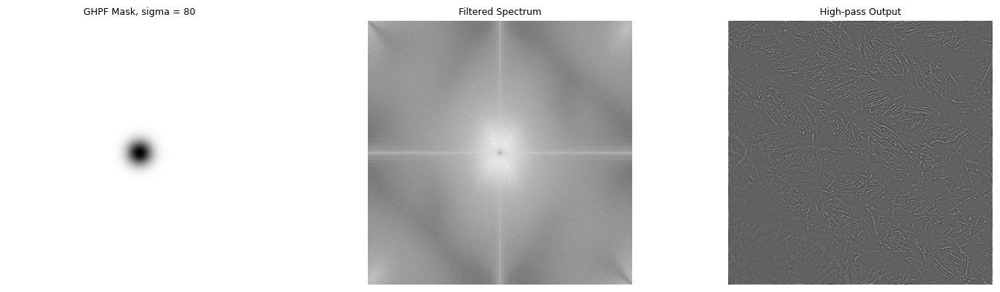

In [60]:
gray = images['100% Cotton']['gray']
sigma = 80

# Create the Gaussian high-pass filter
H = gaussian_highpass(gray.shape, sigma)
# Apply high-pass filtering
highpass, G_shift = frequency_filter(gray, H)
# Normalize only for visualization
highpass_vis = normalize_for_display(highpass)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap='gray')
plt.title(f'GHPF Mask, sigma = {sigma}')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(G_shift)), cmap='gray')
plt.title('Filtered Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(highpass_vis, cmap='gray')
plt.title('High-pass Output')
plt.axis('off')

plt.tight_layout()
plt.show()

1. Cotton

    The GHPF strongly emphasizes numerous short and irregular fiber boundaries in the cotton sample, while slowly varying yarn regions are suppressed.

2. Linen-rayon

    In the linen-rayon sample, the strongest responses mainly occur along loose individual filaments and yarn boundaries, while the smoother yarn interiors produce weaker responses.

3. Polyester

    The polyester result clearly preserves the repeated diagonal yarn boundaries, showing that its regular directional texture contains strong high-frequency structure.

Because each high-pass image is normalized independently to [0, 255], their displayed brightness should not be used to compare the absolute amount of high-frequency energy between fabrics.

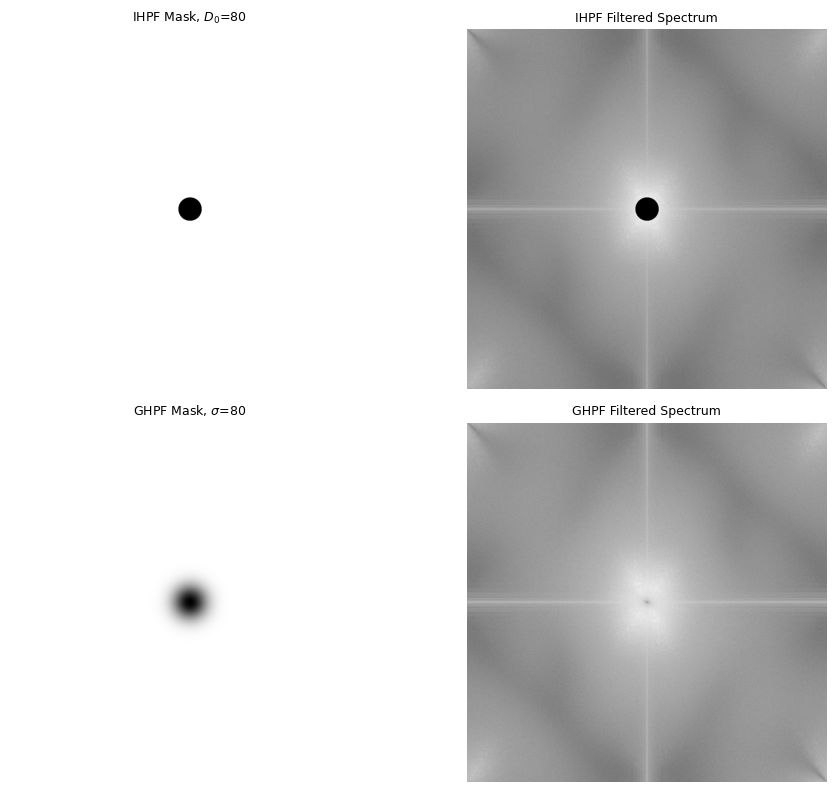

In [61]:
gray = images['100% Cotton']['gray']

D0 = 80
sigma = 80

# Create high-pass filters
H_ihpf = ideal_highpass(gray.shape, D0)
H_ghpf = gaussian_highpass(gray.shape, sigma)

# Apply the filters
_, G_ihpf = frequency_filter(gray, H_ihpf)
_, G_ghpf = frequency_filter(gray, H_ghpf)

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(H_ihpf, cmap='gray')
plt.title(f'IHPF Mask, $D_0$={D0}')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(np.log1p(np.abs(G_ihpf)), cmap='gray')
plt.title('IHPF Filtered Spectrum')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(H_ghpf, cmap='gray')
plt.title(f'GHPF Mask, $\\sigma$={sigma}')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(np.log1p(np.abs(G_ghpf)), cmap='gray')
plt.title('GHPF Filtered Spectrum')
plt.axis('off')

plt.tight_layout()

# Save the HPF mask/spectrum figure for the report
plt.savefig(
    save_dir / 'fig_hpf_masks.png',
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.03
)

plt.show()


Both IHPF and GHPF suppress slowly varying image regions and emphasize yarn boundaries and fine fibers. The high-pass responses also enhance small intensity variations, so image noise and acquisition artifacts can be amplified together with useful texture. GHPF provides a smoother frequency transition than IHPF, while IHPF uses an abrupt cutoff and is therefore more susceptible to frequency-cutoff artifacts.

# C2.3. Parameter Experiment (GHPF)

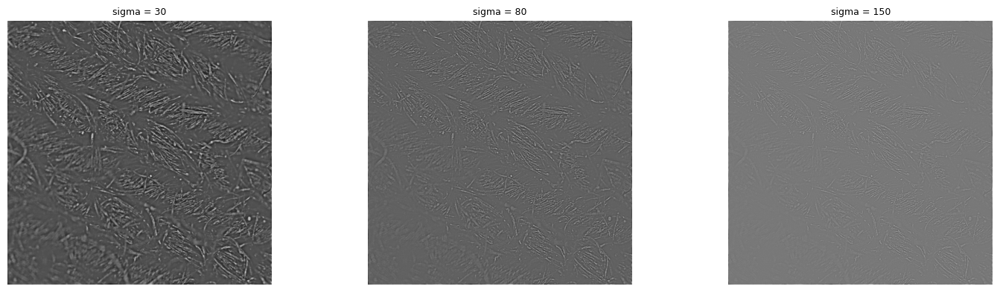

In [62]:
sigma_values = [30, 80, 150]
gray = images['100% Cotton']['gray']

plt.figure(figsize=(15, 4))

for i, sigma in enumerate(sigma_values):
    # Create the Gaussian high-pass filter
    H = gaussian_highpass(gray.shape, sigma)

    # Apply the filter
    highpass, _ = frequency_filter(gray, H)

    # Normalize only for visualization
    highpass_vis = normalize_for_display(highpass)

    plt.subplot(1, 3, i + 1)
    plt.imshow(highpass_vis, cmap='gray')
    plt.title(f'sigma = {sigma}')
    plt.axis('off')

plt.tight_layout()
plt.show()

At $\sigma=30$, many fine cotton fibers produce strong responses. At $\sigma=80$, weaker texture components are suppressed while the main fiber boundaries remain visible. At $\sigma=150$, only very high-frequency structures remain and the response becomes much weaker. Therefore, increasing $\sigma$ makes the GHPF more selective toward higher frequencies.

# High-frequency Enhancement

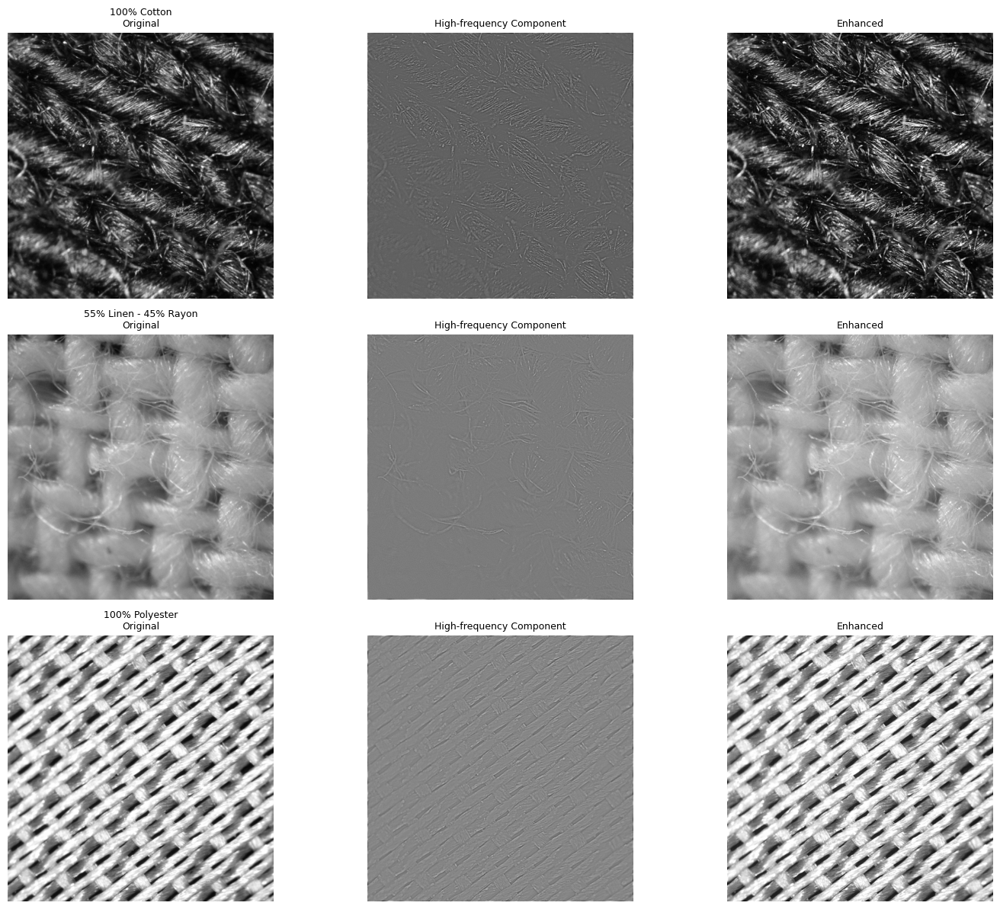

In [63]:
sigma = 80
alpha = 1.0

plt.figure(figsize=(15, 12))

for i, (name, img) in enumerate(images.items()):
    gray = img['gray']

    # Extract the signed high-frequency component
    H = gaussian_highpass(gray.shape, sigma)
    highpass, _ = frequency_filter(gray, H)
    # Normalize only for visualization
    highpass_vis = normalize_for_display(highpass)
    # Add the high-frequency component back to the original image
    enhanced = gray.astype(float) + alpha * highpass
    enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)
    # Display the original image
    plt.subplot(3, 3, i * 3 + 1)
    plt.imshow(gray, cmap='gray')
    plt.title(name + '\nOriginal')
    plt.axis('off')
    # Display the extracted high-frequency component
    plt.subplot(3, 3, i * 3 + 2)
    plt.imshow(highpass_vis, cmap='gray')
    plt.title('High-frequency Component')
    plt.axis('off')
    # Display the enhanced image
    plt.subplot(3, 3, i * 3 + 3)
    plt.imshow(enhanced, cmap='gray')
    plt.title('Enhanced')
    plt.axis('off')

plt.tight_layout()
plt.show()

# D. Spatial- and frequency-domain comparison

D1. Spatial Gaussian

In [64]:
def spatial_gaussian(gray):
    return cv2.GaussianBlur(gray, (3, 3), 0)

D2. Spatial Laplacian

In [65]:
def spatial_laplacian(gray):
    return cv2.Laplacian(gray, cv2.CV_64F, ksize=3)

D3. Low-pass comparison

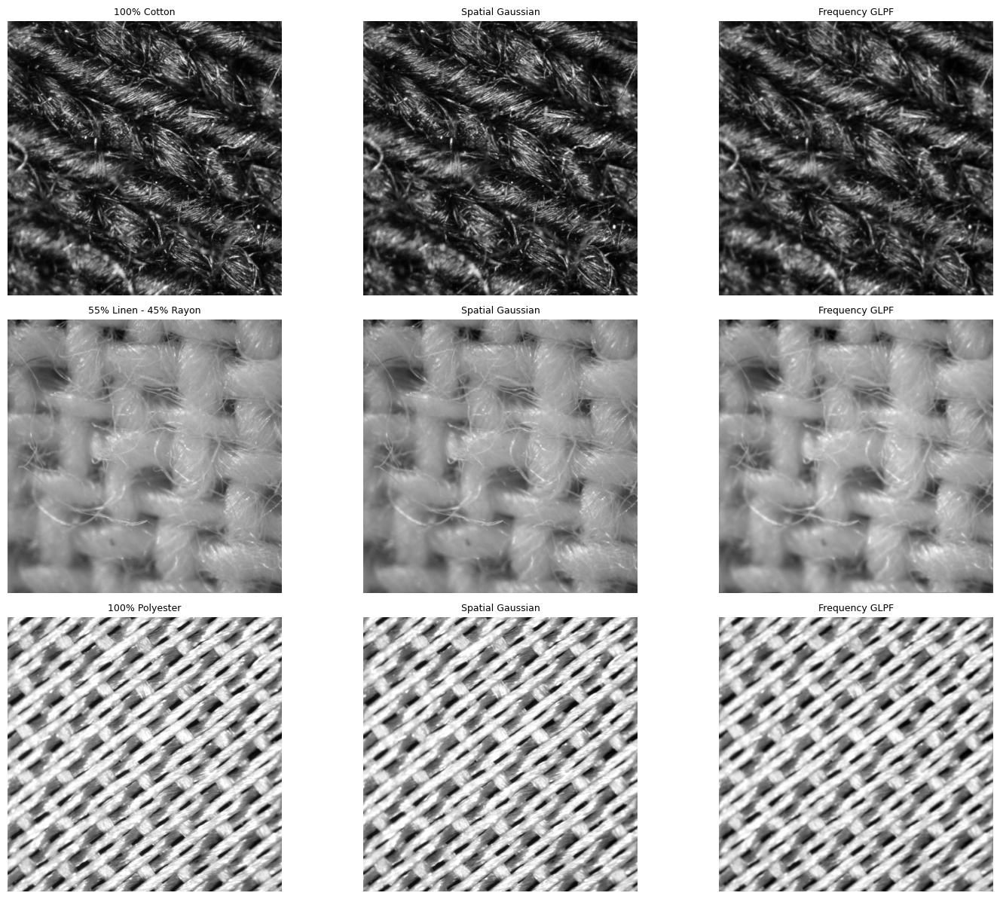

In [66]:
sigma = 80

plt.figure(figsize=(15, 12))

for i, (name, img) in enumerate(images.items()):
    gray = img['gray']

    # Apply spatial Gaussian smoothing
    spatial_result = spatial_gaussian(gray)
    # Apply Gaussian low-pass filtering in the frequency domain
    H = gaussian_lowpass(gray.shape, sigma)
    frequency_result, _ = frequency_filter(gray, H)
    # Display the original image
    plt.subplot(3, 3, i * 3 + 1)
    plt.imshow(gray, cmap='gray')
    plt.title(name)
    plt.axis('off')
    # Display spatial-domain smoothing
    plt.subplot(3, 3, i * 3 + 2)
    plt.imshow(spatial_result, cmap='gray')
    plt.title('Spatial Gaussian')
    plt.axis('off')
    # Display frequency-domain smoothing
    plt.subplot(3, 3, i * 3 + 3)
    plt.imshow(frequency_result, cmap='gray')
    plt.title('Frequency GLPF')
    plt.axis('off')

plt.tight_layout()
plt.show()

 Both methods preserve the dominant fabric structures. The 3×3 spatial Gaussian produces only mild local smoothing, whereas GLPF with $\sigma=80$ causes stronger smoothing in all three samples. The effect is particularly visible in cotton fine fibers and in the softened boundaries of the polyester weave.

D4. High-pass comparison

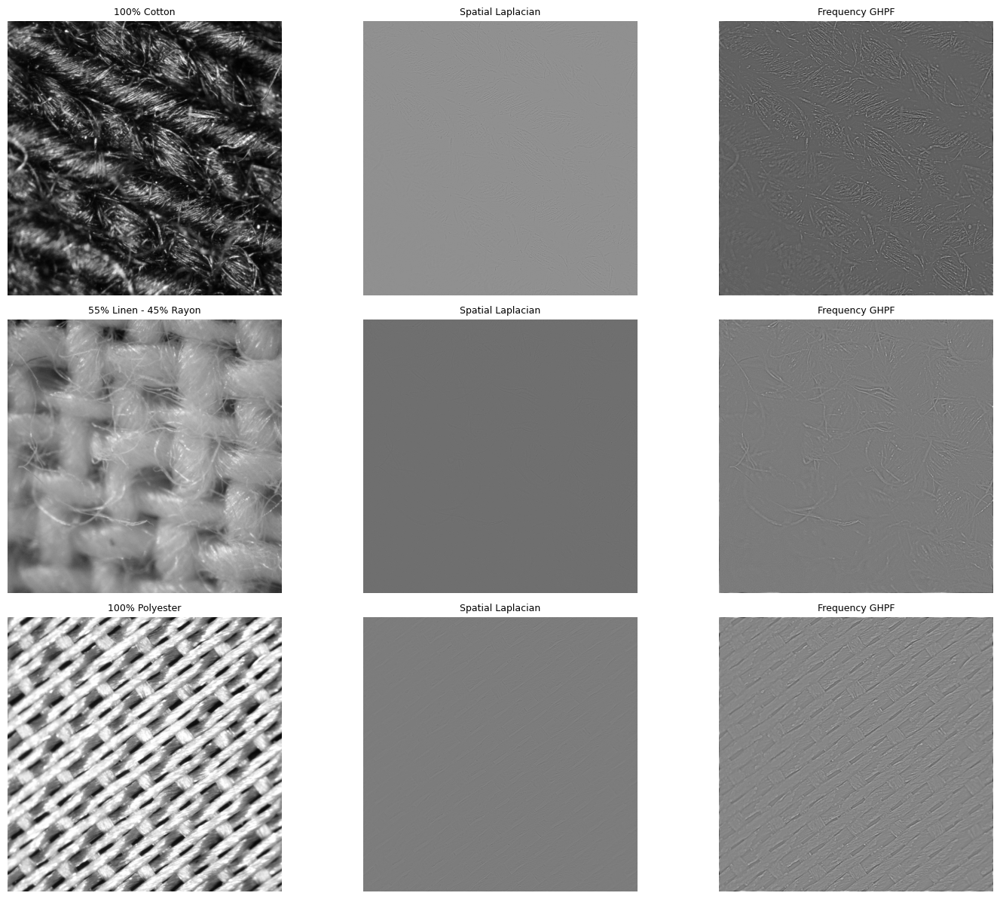

In [67]:
sigma = 80

plt.figure(figsize=(15, 12))

for i, (name, img) in enumerate(images.items()):
    gray = img['gray']

    # Compute the spatial Laplacian response
    spatial_hp = spatial_laplacian(gray)
    # Normalize the Laplacian response only for visualization
    spatial_vis = normalize_for_display(spatial_hp)
    # Compute the Gaussian high-pass response
    H = gaussian_highpass(gray.shape, sigma)
    frequency_hp, _ = frequency_filter(gray, H)
    # Normalize the frequency-domain response only for visualization
    frequency_vis = normalize_for_display(frequency_hp)
    # Display the original image
    plt.subplot(3, 3, i * 3 + 1)
    plt.imshow(gray, cmap='gray')
    plt.title(name)
    plt.axis('off')
    # Display spatial high-pass response
    plt.subplot(3, 3, i * 3 + 2)
    plt.imshow(spatial_vis, cmap='gray')
    plt.title('Spatial Laplacian')
    plt.axis('off')
    # Display frequency high-pass response
    plt.subplot(3, 3, i * 3 + 3)
    plt.imshow(frequency_vis, cmap='gray')
    plt.title('Frequency GHPF')
    plt.axis('off')

plt.tight_layout()
plt.show()

Both methods respond to intensity transitions, but the current Laplacian visualization shows relatively weak contrast, whereas GHPF reveals the textile structures more clearly. In cotton, GHPF emphasizes numerous irregular fibers; in linen-rayon, it mainly highlights loose filaments and yarn boundaries; and in polyester, it clearly preserves the repeated diagonal weave pattern.

D5. Runtime comparison

In [68]:
import time

gray = images['100% Cotton']['gray']
times = []

# Measure spatial Gaussian filtering time
start = time.perf_counter()
_ = spatial_gaussian(gray)
spatial_gaussian_time = time.perf_counter() - start
# Measure frequency GLPF time
start = time.perf_counter()
H = gaussian_lowpass(gray.shape, 80)
_ = frequency_filter(gray, H)
frequency_glpf_time = time.perf_counter() - start
# Measure spatial Laplacian time
start = time.perf_counter()
_ = spatial_laplacian(gray)
spatial_laplacian_time = time.perf_counter() - start
# Measure frequency GHPF time
start = time.perf_counter()
H = gaussian_highpass(gray.shape, 80)
_ = frequency_filter(gray, H)
frequency_ghpf_time = time.perf_counter() - start

runtime = pd.DataFrame({
    'Method': [
        'Spatial Gaussian',
        'Frequency GLPF',
        'Spatial Laplacian',
        'Frequency GHPF'
    ],
    'Time (s)': [
        spatial_gaussian_time,
        frequency_glpf_time,
        spatial_laplacian_time,
        frequency_ghpf_time
    ]
})

display(runtime)

,Method,Time (s)
0,Spatial Gaussian,0.004673
1,Frequency GLPF,0.494726
2,Spatial Laplacian,0.012122
3,Frequency GHPF,0.446906


For the 2464×2464 cotton image, the spatial filters are substantially faster than the frequency-domain implementations. Spatial Gaussian requires about 0.010 s compared with 1.227 s for GLPF, while spatial Laplacian requires about 0.025 s compared with 0.852 s for GHPF. For these simple spatial filters, FFT computation introduces additional overhead.

D6. Comparison table

In [69]:
comparison = pd.DataFrame({
    'Method': ['Gaussian filter', 'Gaussian low-pass filter', 'Laplacian filter', 'Gaussian high-pass filter'],
    'Domain': ['Spatial', 'Frequency', 'Spatial', 'Frequency'],
    'Visual effect': ['Local smoothing', 'Frequency-based smoothing', 'Local edge response', 'High-frequency extraction'],
    'Detail / edge preservation': ['Reduces fine details', 'Controlled by sigma', 'Emphasizes abrupt edges', 'Emphasizes fine texture and edges'],
    'Noise / artifact behavior': ['Reduces local noise', 'Suppresses high-frequency noise', 'May amplify noise', 'May amplify high-frequency noise'],
    'Suitability': ['Useful for mild denoising', 'Useful for controllable smoothing', 'Useful for local texture enhancement', 'Relevant to enhancement before CNN classification']
})

display(comparison)

,Method,Domain,Visual effect,Detail / edge preservation,Noise / artifact behavior,Suitability
0,Gaussian filter,Spatial,Local smoothing,Reduces fine details,Reduces local noise,Useful for mild denoising
1,Gaussian low-pass filter,Frequency,Frequency-based smoothing,Controlled by sigma,Suppresses high-frequency noise,Useful for controllable smoothing
2,Laplacian filter,Spatial,Local edge response,Emphasizes abrupt edges,May amplify noise,Useful for local texture enhancement
3,Gaussian high-pass filter,Frequency,High-frequency extraction,Emphasizes fine texture and edges,May amplify high-frequency noise,Relevant to enhancement before CNN classification


Spatial filtering is faster for the small local filters used in this experiment. Frequency-domain filtering provides more direct control over which frequency components are suppressed or retained. For the final textile-classification project, GHPF-based enhancement is particularly relevant because its frequency parameter can control the amount of microscopic texture emphasized before CNN classification.